# **Modelado Predictivo del Nivel del Río en la Estación Hidrológica "El Banco - Aut" Mediante Aprendizaje Automático Supervisado**

# **1. Descripción del problema e inspección del conjunto de datos**
# **1.1. Descripción del problema**

Este proyecto aborda un problema de predicción de series de tiempo mediante aprendizaje automático supervisado, enfocado específicamente en pronosticar el nivel del río Magdalena en la estación automática "EL BANCO - AUT" (Código: 25027020).

El conjunto de datos oficial, obtenido a través del portal: "https://www.datos.gov.co/Ambiente-y-Desarrollo-Sostenible/Nivel-Instant-neo-del-Rio/bdmn-sqnh/about_data", contiene originalmente 12 variables. A continuación se muestra una descripción de las variables:
*   CodigoEstacion: Identificación de la estación dentro del catálogo de estaciones.
*   CodigoSensor: Código de identificación asignado al sensor.
*   FechaObservación: Fecha en la cual se realiza la medición.
*   ValorObservado: Valor medido.
*   NombreEstacion: Identificación de la estación dentro del catálogo de estaciones.
*   Departamento: Nombre del departamento donde se ubica la estación.
*   Municipio: Nombre del Municipio donde se localiza la estación.
*   ZonaHidrografica: Zona hidrográfica sobre la cual está ubicada la estación.
*   Latitud: Latitud en la cual se ubica la estación.
*   Longitud: Longitud en la cual se ubica la estación.
*   DescripcionSensor: Nivel instantáneo.
*   UnidadMedida: Metros.

Dado que el estudio se enfoca en el comportamiento histórico y predictivo de una estación hidrológica, el alcance del preprocesamiento se delimita únicamente a las variables  *FechaObservada* y *ValorObservado*, descartando las demás variables que no aportan valor directo al modelo.



# **1.2. Importación de librerías**
Se utilizan librerías como pandas y seaborn para la inspección y exploración de los datos.

In [19]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# **1.3. Carga del dataset**
Se toman únicamente las dos variables de interés para nuestro análisis.

In [20]:
columnas_deseadas = ["FechaObservacion", "ValorObservado"]
df = pd.read_csv("Nivel_Instantáneo_del_Rio_20261020.csv", usecols=columnas_deseadas)

df.info()
display(df.head())

<class 'pandas.DataFrame'>
RangeIndex: 315876 entries, 0 to 315875
Data columns (total 2 columns):
 #   Column            Non-Null Count   Dtype
---  ------            --------------   -----
 0   FechaObservacion  315876 non-null  str  
 1   ValorObservado    315876 non-null  str  
dtypes: str(2)
memory usage: 4.8 MB


,FechaObservacion,ValorObservado
0,2011 Aug 15 11:00:00 AM,"6,73"
1,2005 Nov 15 02:00:00 PM,"6,15"
2,2011 May 10 05:00:00 AM,"9,43"
3,2009 Apr 29 07:00:00 AM,"7,25"
4,2016 Sep 17 07:00:00 PM,"6,12"


Las variables *FechaObservada* y *ValorObservado* son de tipo object, se procede a hacer el cambio a tipo datetime y float respectivamente.

In [21]:
df["FechaObservacion"] = pd.to_datetime(df["FechaObservacion"], errors="coerce")

df["ValorObservado"] = df["ValorObservado"].astype(str).str.replace(",", ".", regex=False)
df["ValorObservado"] = pd.to_numeric(df["ValorObservado"], errors="coerce")

df.info()
display(df.head())

<class 'pandas.DataFrame'>
RangeIndex: 315876 entries, 0 to 315875
Data columns (total 2 columns):
 #   Column            Non-Null Count   Dtype         
---  ------            --------------   -----         
 0   FechaObservacion  315876 non-null  datetime64[us]
 1   ValorObservado    315876 non-null  float64       
dtypes: datetime64[us](1), float64(1)
memory usage: 4.8 MB


,FechaObservacion,ValorObservado
0,2011-08-15 11:00:00,6.73
1,2005-11-15 14:00:00,6.15
2,2011-05-10 05:00:00,9.43
3,2009-04-29 07:00:00,7.25
4,2016-09-17 19:00:00,6.12


Se ordenan cronológicamente los registros.

In [22]:
df = df.sort_values(by="FechaObservacion", ascending=True).reset_index(drop=True)

display(df.head())
display(df.tail())

,FechaObservacion,ValorObservado
0,2005-01-01 17:00:00,8.65
1,2005-01-01 18:00:00,8.65
2,2005-01-01 19:00:00,8.66
3,2005-01-01 20:00:00,8.69
4,2005-01-01 21:00:00,8.67


,FechaObservacion,ValorObservado
315871,2026-10-19 19:00:00,5.05
315872,2026-10-19 20:00:00,5.06
315873,2026-10-19 21:00:00,5.06
315874,2026-10-19 22:00:00,5.08
315875,2026-10-19 23:00:00,5.09


# **1.4. Inspección inicial**
Se revisan valores faltantes, fechas duplicadas, posibles registros duplicados y valores
numéricos atípicos o imposibles.

In [23]:
print("\nResumen de valores faltantes:")
print(df.isna().sum())
df_fechas_duplicadas = df[df["FechaObservacion"].duplicated()].copy()
print("\nFechas duplicadas:", df["FechaObservacion"].duplicated().sum())
display(df_fechas_duplicadas.head())
print("\nRegistros duplicados:", df.duplicated().sum())

print("\nResumen de variable 'ValorObservado':")
display(df.select_dtypes(include="number").describe().T)

# Calcular Q1, Q3 e IQR
Q1 = df["ValorObservado"].quantile(0.25)
Q3 = df["ValorObservado"].quantile(0.75)
IQR = Q3 - Q1

# Definir los límites superior e inferior
limite_inferior = Q1 - (1.5 * IQR)
limite_superior = Q3 + (1.5 * IQR)

# Filtrar los valores atípicos
outliers = df[(df["ValorObservado"] < limite_inferior) | (df["ValorObservado"] > limite_superior)]

print(f"\nCantidad de valores atípicos encontrados: {len(outliers)}")
display(outliers.head())


Resumen de valores faltantes:
FechaObservacion    0
ValorObservado      0
dtype: int64

Fechas duplicadas: 18054


,FechaObservacion,ValorObservado
102491,2019-08-28 00:00:00,6.39
102492,2019-08-28 00:00:00,6.39
102494,2019-08-28 01:00:00,6.39
102495,2019-08-28 01:00:00,6.39
102497,2019-08-28 02:00:00,6.39



Registros duplicados: 18054

Resumen de variable 'ValorObservado':


,count,mean,std,min,25%,50%,75%,max
ValorObservado,315876.0,6.538216,1.397943,0.0,5.77,6.47,7.29,172.42



Cantidad de valores atípicos encontrados: 926


,FechaObservacion,ValorObservado
2572,2005-04-22 17:00:00,20.49
2573,2005-04-22 19:00:00,167.67
4683,2005-07-22 03:00:00,172.42
18578,2007-02-22 13:00:00,2.40
18579,2007-02-22 14:00:00,2.40


Se puede observar que no hay valores faltantes, pero sí 18054 registros duplicados. Como el número de fechas repetidas es igual al número de filas repetidas, cada fecha repetida trae exactamente el mismo valor; es decir, son copias exactas que envió el sensor y se pueden eliminar sin perder información.

Con el método del rango intercuartílico (IQR) se encontraron 926 valores atípicos, tanto por debajo del límite inferior (por ejemplo 2.40 m) como por encima del límite superior (por ejemplo 167.67 m y 172.42 m).

Antes de tratar los atípicos se eliminan los duplicados, dejando un único registro.

In [24]:
df = df.drop_duplicates().reset_index(drop=True)

#Verificamos duplicados restantes
print("\nFechas duplicadas restantes:", df["FechaObservacion"].duplicated().sum())
print("\nRegistros duplicados restantes:", df.duplicated().sum())



Fechas duplicadas restantes: 0

Registros duplicados restantes: 0


Primero se recalculan los límites del IQR sobre los datos ya sin duplicados y se revisan los valores más bajos y más altos de la serie.

In [25]:
# Se trabaja sobre el DataFrame ya SIN duplicados y ordenado en el tiempo
df = df.sort_values("FechaObservacion").reset_index(drop=True)

# Se recalculan los límites del IQR sobre los datos sin duplicados
Q1 = df["ValorObservado"].quantile(0.25)
Q3 = df["ValorObservado"].quantile(0.75)
IQR = Q3 - Q1
limite_inferior = Q1 - 1.5 * IQR
limite_superior = Q3 + 1.5 * IQR

df["fuera_iqr"] = (df["ValorObservado"] < limite_inferior) | (df["ValorObservado"] > limite_superior)

print(f"Q1 = {Q1:.2f} m | Q3 = {Q3:.2f} m | IQR = {IQR:.2f} m")
print(f"Límites del IQR: [{limite_inferior:.2f} m , {limite_superior:.2f} m]")
print(f"Registros fuera de los límites: {df['fuera_iqr'].sum()}")
print(f"   por debajo del límite inferior: {(df['ValorObservado'] < limite_inferior).sum()}")
print(f"   por encima del límite superior: {(df['ValorObservado'] > limite_superior).sum()}")

# Valores únicos más altos y más bajos: sirven para ver dónde terminan los valores posibles
valores_unicos = np.sort(df["ValorObservado"].unique())
print("\n15 valores únicos más bajos:", valores_unicos[:15])
print("15 valores únicos más altos:", valores_unicos[-15:])

Q1 = 5.74 m | Q3 = 7.31 m | IQR = 1.57 m
Límites del IQR: [3.39 m , 9.66 m]
Registros fuera de los límites: 720
   por debajo del límite inferior: 224
   por encima del límite superior: 496

15 valores únicos más bajos: [0.   0.14 0.15 0.16 0.17 0.18 0.19 0.2  0.21 0.3  2.4  2.63 3.74 3.82
 3.83]
15 valores únicos más altos: [ 10.59  10.6   10.61  10.62  10.63  10.64  15.36  17.92  20.49  28.16
  29.78  52.28  87.22 167.67 172.42]


Los límites del IQR quedaron en 3.39 m y 9.66 m, con 224 registros por debajo y 496 por encima.

En la lista de valores más altos se ve que los niveles aumentan de forma continua hasta 10.64 m y luego saltan a 15.36 m, sin valores intermedios. Ese salto de casi 5 m marca dónde terminan los valores posibles, por lo que se toma 15 m como límite físico máximo.

En la lista de valores más bajos ocurre algo parecido: hay valores entre 0 y 0.3 m y luego el siguiente es 2.4 m. Un nivel de pocos centímetros no es posible en este punto del río, por lo que se toma 1 m como límite físico mínimo.

## **1.4.1. Clasificación de los valores atípicos**

El método IQR solo indica qué tan lejos está un dato del centro de la distribución, pero no indica si ese dato es un error. En una serie de nivel de río esto importa, porque los valores más altos pueden ser crecientes reales del río y los más bajos pueden ser temporadas secas. Si se eliminan, el modelo nunca vería esos eventos, y son justamente los más importantes de predecir.

Por esta razón, en vez de eliminar todo lo que el IQR marca, cada registro se clasifica con reglas basadas en el comportamiento físico del río:

| Categoría | Regla | Tratamiento |
|---|---|---|
| Error: valor imposible | Nivel ≤ 1 m o ≥ 15 m | Se elimina |
| Error: sensor pegado | El mismo valor exacto se repite 24 horas o más | Se elimina |
| Error: pico | El valor se aleja más de 1 m de la mediana de las 24 horas a su alrededor | Se elimina |
| Extremo real | Está fuera de los límites del IQR pero no cumple ninguna de las reglas anteriores | Se conserva |

### **Regla 1: valores físicamente imposibles**
Un nivel por debajo de 1 m significa que el sensor no registró bien la medición, ya que el río no baja a ese nivel en este punto. Los valores por encima del límite físico máximo corresponden a errores de transmisión.

In [29]:
# Regla 1: valores físicamente imposibles
# Un nivel por debajo de 1 m no es posible en este punto del río, y valores
# muy por encima del máximo plausible son errores de transmisión.
LIMITE_FISICO_MIN = 1.0   # metros. Hay un salto de 0.3 m a 2.4 m en los valores más bajos
LIMITE_FISICO_MAX = 15.0  # metros. Hay un salto de 10.64 m a 15.36 m en los valores más altos

df["imposible"] = (df["ValorObservado"] < LIMITE_FISICO_MIN) | (df["ValorObservado"] >= LIMITE_FISICO_MAX)

print(f"Registros con valores imposibles: {df['imposible'].sum()}")
imposibles = df.loc[df["imposible"], ["FechaObservacion", "ValorObservado"]]
display(imposibles)

Registros con valores imposibles: 48


,FechaObservacion,ValorObservado
2572,2005-04-22 17:00:00,20.49
2573,2005-04-22 19:00:00,167.67
4683,2005-07-22 03:00:00,172.42
19945,2007-04-22 17:00:00,20.49
19946,2007-04-22 19:00:00,167.67
22056,2007-07-22 03:00:00,172.42
45446,2010-03-25 11:00:00,0.00
61081,2012-01-08 08:00:00,15.36
62265,2012-02-27 05:00:00,87.22
62266,2012-02-27 06:00:00,28.16


Se encontraron 48 registros imposibles, que se pueden agrupar en tres casos:

- **Valores demasiado altos (12 registros):** entre 15.36 m y 172.42 m. Los valores de 2005 (20.49 m y 167.67 m el 22 de abril, y 172.42 m el 22 de julio) se repiten exactamente iguales, en el mismo día y hora, en 2007, lo que indica un error en el registro de los datos y no un comportamiento del río.
- **Valores cercanos a cero (17 registros):** entre el 18 y el 19 de septiembre de 2018 el sensor marcó entre 0.14 m y 0.30 m durante unas 17 horas seguidas, lo que corresponde a una falla continua del sensor.
- **Valores en 0 m (19 registros):** la mayoría ocurre en 2024 y 2025, siempre entre las 03:40 y las 04:00 de la madrugada. Que se repitan a la misma hora sugiere un reinicio o mantenimiento del equipo y no un evento real.

### **Regla 2: sensor pegado**
El sensor mide con precisión de centímetro, así que el nivel de un río real cambia aunque sea un poco a lo largo de un día. Cuando el mismo valor exacto se repite durante muchas horas seguidas, lo más probable es que el sensor dejó de medir y siguió enviando el último dato.

Para encontrar estos casos se divide la serie en tramos donde el valor no cambia. Un tramo nuevo empieza cuando el valor cambia o cuando hay más de 3 horas sin datos, para que un hueco en la serie no una dos tramos distintos.

In [30]:
# Regla 2: sensor pegado (el mismo valor exacto repetido durante muchas horas)
HORAS_PEGADO = 24

# Empieza un "tramo" nuevo cada vez que el valor cambia o cuando hay más de
# 3 horas sin datos (así un hueco largo no une dos tramos distintos)
cambia_valor = df["ValorObservado"].ne(df["ValorObservado"].shift())
salto_tiempo = df["FechaObservacion"].diff() > pd.Timedelta(hours=3)
df["id_tramo"] = (cambia_valor | salto_tiempo).cumsum()

# Duración de cada tramo con valor constante
tramos = df.groupby("id_tramo").agg(
    valor=("ValorObservado", "first"),
    inicio=("FechaObservacion", "min"),
    fin=("FechaObservacion", "max"),
    registros=("ValorObservado", "size"),
)
tramos["duracion_h"] = (tramos["fin"] - tramos["inicio"]).dt.total_seconds() / 3600

print("Tramos en los que el valor no cambió durante:")
for h in [3, 6, 12, 24, 48]:
    print(f"   {h:>2} horas o más: {(tramos['duracion_h'] >= h).sum()} tramos")

tramos_pegados = tramos[tramos["duracion_h"] >= HORAS_PEGADO]
df["pegado"] = df["id_tramo"].isin(tramos_pegados.index)

print(f"\nTramos con sensor pegado (>= {HORAS_PEGADO} h): {len(tramos_pegados)}")
print(f"Registros afectados: {df['pegado'].sum()}")
display(tramos_pegados.sort_values("duracion_h", ascending=False))

Tramos en los que el valor no cambió durante:
    3 horas o más: 4728 tramos
    6 horas o más: 955 tramos
   12 horas o más: 180 tramos
   24 horas o más: 56 tramos
   48 horas o más: 35 tramos

Tramos con sensor pegado (>= 24 h): 56
Registros afectados: 14034


,valor,inicio,fin,registros,duracion_h
id_tramo,,,,,
51392,6.39,2018-12-20 10:00:00,2019-04-02 01:00:00,2464,2463.0
52454,6.39,2019-07-08 18:00:00,2019-09-14 23:00:00,1637,1637.0
42874,4.28,2015-12-26 20:00:00,2016-02-29 08:00:00,1549,1548.0
50373,6.55,2018-07-22 00:00:00,2018-09-17 21:00:00,1390,1389.0
49199,4.27,2018-01-27 23:00:00,2018-03-11 12:00:00,1016,1021.0
53608,5.15,2020-02-25 01:00:00,2020-03-16 21:00:00,501,500.0
53605,5.15,2020-01-25 18:00:00,2020-02-11 20:00:00,411,410.0
49200,4.27,2018-03-11 16:00:00,2018-03-28 13:00:00,403,405.0
52455,6.39,2019-09-18 00:00:00,2019-09-30 11:00:00,300,299.0


La tabla muestra que es normal que el valor se repita algunas horas (955 tramos de 6 h o más), ya que el nivel del río puede mantenerse estable por periodos cortos. Sin embargo, que el mismo valor exacto se mantenga 24 horas o más es poco común (56 tramos), por lo que se toma 24 horas como umbral.

Se encontraron 56 tramos con el sensor pegado, que suman 14034 registros. Algunos duran semanas o meses: el más largo va del 20 de diciembre de 2018 al 2 de abril de 2019, con un valor fijo de 6.39 m durante 2463 horas (unos 103 días). También hay tramos largos de 6.39 m entre julio y septiembre de 2019, de 4.28 m entre diciembre de 2015 y febrero de 2016, y de 6.55 m entre julio y septiembre de 2018. Ningún río mantiene el mismo nivel, al centímetro, durante meses.

La mayoría de estos valores (6.39 m, 6.55 m, 5.15 m, 4.28 m) están dentro de los límites del IQR, por lo que ese método no podía detectarlos: el valor parece normal y lo que lo delata es que no cambia en el tiempo. Además, el tramo de 6.39 m de 2019 coincide con el periodo en que aparecieron los registros duplicados, lo que sugiere una falla general del equipo en esas fechas.

### **Regla 3: picos**
El nivel del río Magdalena cambia de forma gradual. Un valor que sube o baja más de un metro y en la siguiente lectura vuelve a su nivel anterior no corresponde a un comportamiento físico del río, sino a un error de medición.

Para detectarlos se calcula, para cada registro, la mediana de los valores de las 12 horas anteriores y las 12 horas posteriores (mediana móvil centrada de 24 horas). Se usa la mediana y no la media porque la mediana no se deja arrastrar por el mismo pico que se quiere detectar. Si el valor se aleja más de 1 m de esa mediana, se marca como pico.

In [32]:
# Regla 3: picos (un valor que se aleja bruscamente del comportamiento de las horas cercanas)
VENTANA = "24h"
UMBRAL_PICO = 1.0  # metros

serie = df.set_index("FechaObservacion")["ValorObservado"]

# La mediana de referencia se calcula sin los errores ya identificados
ya_es_error = (df["imposible"] | df["pegado"]).to_numpy()
serie_referencia = serie.where(~ya_es_error)

# Mediana móvil centrada: para cada registro, la mediana de las 12 h antes y 12 h después
mediana_movil = serie_referencia.rolling(VENTANA, center=True, min_periods=3).median()
df["desviacion"] = (serie - mediana_movil).abs().to_numpy()

# ¿Qué tan lejos de su mediana suelen estar los datos?
desv_validas = df.loc[~ya_es_error, "desviacion"].dropna()
print("Percentiles de la desviación respecto a la mediana móvil de 24 h (m):")
print(desv_validas.quantile([0.50, 0.90, 0.99, 0.999, 0.9999]).round(3).to_string())

print("\nRegistros que superan cada umbral:")
for u in [0.3, 0.5, 1.0, 2.0, 3.0]:
    print(f"   > {u} m: {(desv_validas > u).sum()}")

df["pico"] = (df["desviacion"] > UMBRAL_PICO) & ~df["imposible"] & ~df["pegado"]
print(f"\nRegistros clasificados como pico (> {UMBRAL_PICO} m): {df['pico'].sum()}")
display(df.loc[df["pico"], ["FechaObservacion", "ValorObservado", "desviacion"]].head(20))

Percentiles de la desviación respecto a la mediana móvil de 24 h (m):
0.5000    0.005
0.9000    0.020
0.9900    0.400
0.9990    1.771
0.9999    3.773

Registros que superan cada umbral:
   > 0.3 m: 2953
   > 0.5 m: 2737
   > 1.0 m: 1276
   > 2.0 m: 228
   > 3.0 m: 71

Registros clasificados como pico (> 1.0 m): 1276


,FechaObservacion,ValorObservado,desviacion
4976,2005-08-03 12:00:00,8.70,1.005
4978,2005-08-03 14:00:00,8.68,1.005
4979,2005-08-03 15:00:00,8.68,1.010
4984,2005-08-03 20:00:00,8.68,1.055
4985,2005-08-03 21:00:00,8.67,1.050
4986,2005-08-03 22:00:00,8.65,1.040
4987,2005-08-03 23:00:00,8.65,1.065
5000,2005-08-04 12:00:00,8.62,1.115
5001,2005-08-04 13:00:00,8.63,1.130
5002,2005-08-04 14:00:00,8.64,1.145


El 99.9 % de los registros se aleja menos de [valor del percentil 0.999] m de su mediana, así que un umbral de 1 m está muy por encima de la variación normal de la serie y solo marca los saltos bruscos. Se encontraron [N] picos.

### **Clasificación final y comparación con el IQR**

In [14]:
# Clasificación final de cada registro (si cumple varias reglas, gana la de más abajo)
df["tipo_atipico"] = "normal"
df.loc[df["fuera_iqr"], "tipo_atipico"] = "extremo_real"
df.loc[df["pico"], "tipo_atipico"] = "error_pico"
df.loc[df["pegado"], "tipo_atipico"] = "error_sensor_pegado"
df.loc[df["imposible"], "tipo_atipico"] = "error_imposible"

# Comparación: qué hubiera hecho el IQR solo frente a la clasificación por reglas
tabla_comparacion = pd.crosstab(
    df["tipo_atipico"],
    df["fuera_iqr"].map({True: "Fuera del IQR", False: "Dentro del IQR"}),
    margins=True, margins_name="Total",
    rownames=["Clasificación"], colnames=["Según IQR"],
)
display(tabla_comparacion)

es_error = df["tipo_atipico"].str.startswith("error")
print(f"Atípicos según IQR: {df['fuera_iqr'].sum()}")
print(f"   de ellos son extremos reales (se conservan): {(df['tipo_atipico'] == 'extremo_real').sum()}")
print(f"   de ellos son errores: {(df['fuera_iqr'] & es_error).sum()}")
print(f"Errores que el IQR NO detectaba: {(~df['fuera_iqr'] & es_error).sum()}")

# ¿Cuándo ocurren los extremos reales? Si son reales, deberían concentrarse
# en ciertos años y temporadas, no repartirse al azar
extremos = df[df["tipo_atipico"] == "extremo_real"]
nivel = np.where(extremos["ValorObservado"] > limite_superior, "Nivel alto", "Nivel bajo")

print("\nExtremos reales por año:")
display(pd.crosstab(extremos["FechaObservacion"].dt.year, nivel, rownames=["Año"], colnames=["Tipo"]))
print("Extremos reales por mes:")
display(pd.crosstab(extremos["FechaObservacion"].dt.month, nivel, rownames=["Mes"], colnames=["Tipo"]))

Según IQR,Dentro del IQR,Fuera del IQR,Total
Clasificación,,,
error_imposible,0,31,31
error_pico,919,358,1277
error_sensor_pegado,13882,152,14034
extremo_real,0,179,179
normal,282301,0,282301
Total,297102,720,297822


Atípicos según IQR: 720
   de ellos son extremos reales (se conservan): 179
   de ellos son errores: 541
Errores que el IQR NO detectaba: 14801

Extremos reales por año:


Tipo,Nivel alto,Nivel bajo
Año,,
2007,0,18
2018,0,17
2020,35,0
2022,109,0


Extremos reales por mes:


Tipo,Nivel alto,Nivel bajo
Mes,,
2,0,18
9,0,17
10,78,0
11,26,0
12,40,0


La tabla compara qué hubiera pasado si se usara solo el IQR:
- De los [N] registros que el IQR marcaba como atípicos, [N] son extremos reales que se conservan y [N] son errores.
- Además, el IQR no detectaba [N] errores que tienen valores dentro del rango normal (picos o tramos pegados).

Los extremos reales no aparecen repartidos al azar: se concentran en [años] y en los meses de [meses]. [Comparar con las temporadas de lluvia; por ejemplo, durante la temporada de lluvias 2010-2011, asociada al fenómeno de La Niña, el río Magdalena se desbordó y varios municipios del departamento del Magdalena se inundaron (El Universal, 2012).] Esto respalda que son crecientes reales y no fallas del sensor.

### **Gráficas de la clasificación**

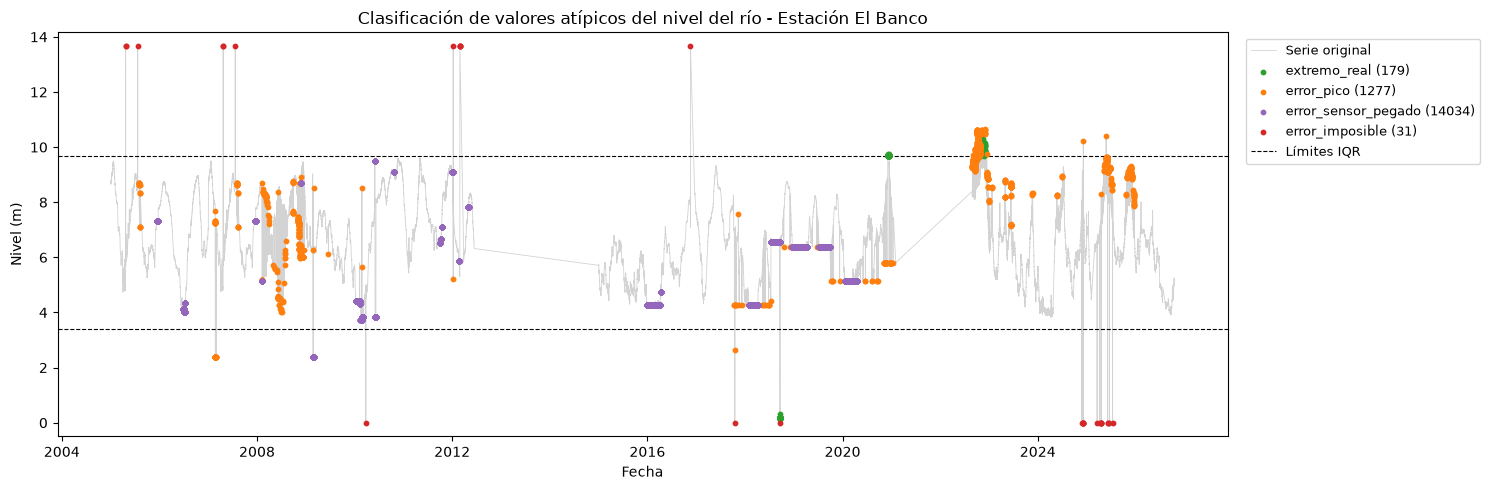

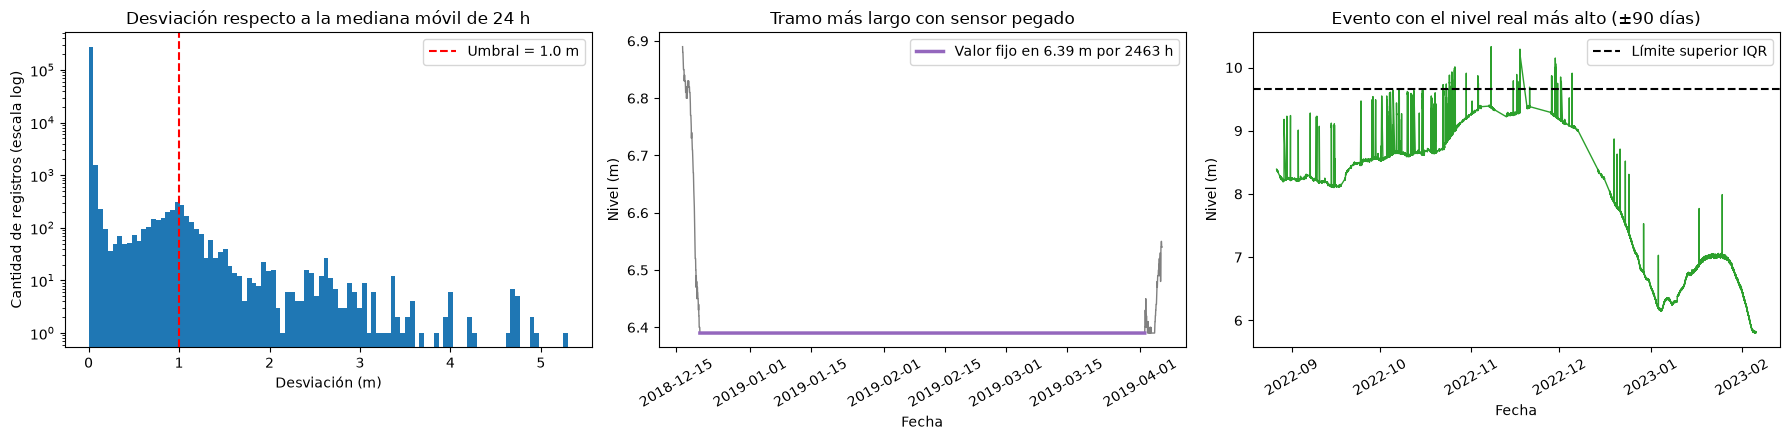

In [15]:
colores = {
    "extremo_real": "#2ca02c",
    "error_pico": "#ff7f0e",
    "error_sensor_pegado": "#9467bd",
    "error_imposible": "#d62728",
}
tope_y = limite_superior + 4  # tope del eje para que los valores de 172 m no aplasten la gráfica

# Figura 1: serie completa con cada tipo de atípico marcado
fig, ax = plt.subplots(figsize=(15, 5))
ax.plot(df["FechaObservacion"], df["ValorObservado"].clip(upper=tope_y),
        color="lightgray", linewidth=0.6, label="Serie original")
for tipo, color in colores.items():
    sub = df[df["tipo_atipico"] == tipo]
    ax.scatter(sub["FechaObservacion"], sub["ValorObservado"].clip(upper=tope_y),
               s=10, color=color, label=f"{tipo} ({len(sub)})", zorder=3)
ax.axhline(limite_superior, color="black", linestyle="--", linewidth=0.8, label="Límites IQR")
ax.axhline(limite_inferior, color="black", linestyle="--", linewidth=0.8)
ax.set_ylim(-0.5, tope_y + 0.5)
ax.set_title("Clasificación de valores atípicos del nivel del río - Estación El Banco")
ax.set_xlabel("Fecha")
ax.set_ylabel("Nivel (m)")
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1), fontsize=9)
plt.tight_layout()
plt.show()

# Figura 2: evidencia de cada regla
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))

# (a) Distribución de la desviación: justifica el umbral de picos
axes[0].hist(desv_validas, bins=100, color="#1f77b4")
axes[0].set_yscale("log")
axes[0].axvline(UMBRAL_PICO, color="red", linestyle="--", label=f"Umbral = {UMBRAL_PICO} m")
axes[0].set_title("Desviación respecto a la mediana móvil de 24 h")
axes[0].set_xlabel("Desviación (m)")
axes[0].set_ylabel("Cantidad de registros (escala log)")
axes[0].legend()

# (b) Zoom al tramo pegado más largo
if len(tramos_pegados) > 0:
    t = tramos_pegados.sort_values("duracion_h").iloc[-1]
    ventana = df[(df["FechaObservacion"] >= t["inicio"] - pd.Timedelta(days=4)) &
                 (df["FechaObservacion"] <= t["fin"] + pd.Timedelta(days=4))]
    axes[1].plot(ventana["FechaObservacion"], ventana["ValorObservado"], color="gray", linewidth=1)
    pegados = ventana[ventana["pegado"]]
    axes[1].plot(pegados["FechaObservacion"], pegados["ValorObservado"], color="#9467bd",
                 linewidth=2.5, label=f"Valor fijo en {t['valor']} m por {t['duracion_h']:.0f} h")
    axes[1].legend()
axes[1].set_title("Tramo más largo con sensor pegado")
axes[1].set_xlabel("Fecha")
axes[1].set_ylabel("Nivel (m)")
axes[1].tick_params(axis="x", rotation=30)

# (c) Zoom al evento con el extremo real más alto: la subida es gradual
if len(extremos) > 0:
    fecha_max = extremos.loc[extremos["ValorObservado"].idxmax(), "FechaObservacion"]
    ventana = df[(df["FechaObservacion"] >= fecha_max - pd.Timedelta(days=90)) &
                 (df["FechaObservacion"] <= fecha_max + pd.Timedelta(days=90)) &
                 ~df["tipo_atipico"].str.startswith("error")]
    axes[2].plot(ventana["FechaObservacion"], ventana["ValorObservado"], color="#2ca02c", linewidth=1)
    axes[2].axhline(limite_superior, color="black", linestyle="--", label="Límite superior IQR")
    axes[2].legend()
axes[2].set_title("Evento con el nivel real más alto (±90 días)")
axes[2].set_xlabel("Fecha")
axes[2].set_ylabel("Nivel (m)")
axes[2].tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.show()

**Figura 1.** [Describir: dónde aparecen los errores y los extremos reales a lo largo de la serie. Los errores son puntos aislados o tramos planos; los extremos reales forman curvas continuas.]

**Figura 2.**
- **(a)** Casi todos los registros se alejan muy poco de su mediana móvil; el umbral de 1 m queda lejos de esa masa de datos y solo separa los saltos bruscos.
- **(b)** El tramo pegado se ve como una línea totalmente plana que rompe la curva normal del río, con un cambio brusco al empezar y al terminar.
- **(c)** El evento con el nivel real más alto sube y baja de forma gradual durante semanas. Ese es el comportamiento de una creciente real, y por eso se conserva aunque supere el límite del IQR.

### **Tratamiento de los errores**
Los registros clasificados como error se convierten en valores nulos; los extremos reales no se modifican.

Luego se aplica interpolación en el tiempo solo en huecos cortos: aquellos donde entre el último dato válido y el siguiente hay como máximo 4 horas. El límite se mide en tiempo y no en número de filas porque el sensor no siempre mide con la misma frecuencia (a veces cada hora, a veces cada 10 minutos). Los huecos más largos se dejan vacíos, porque rellenarlos con una línea recta sería inventar el comportamiento del río.

In [16]:
# Se guarda una copia con la clasificación por si se necesita más adelante
df_clasificado = df.copy()

# 1. Los errores se convierten en nulos. Los extremos reales NO se tocan
es_error = df["tipo_atipico"].str.startswith("error")
df["ValorObservado"] = df["ValorObservado"].mask(es_error)
print(f"Errores convertidos en nulos: {es_error.sum()}")

# 2. Interpolación solo en huecos cortos, medidos en TIEMPO y no en número de filas,
#    porque el sensor a veces mide cada hora y a veces cada 10 minutos
MAX_HUECO = pd.Timedelta(hours=4)

serie = df.set_index("FechaObservacion")["ValorObservado"]
es_nulo = serie.isna()
tiempos = serie.index.to_series()
anterior_valido = tiempos.where(~es_nulo).ffill()   # fecha del último dato bueno antes del hueco
siguiente_valido = tiempos.where(~es_nulo).bfill()  # fecha del primer dato bueno después del hueco
duracion_hueco = siguiente_valido - anterior_valido

rellenable = es_nulo & (duracion_hueco <= MAX_HUECO)
interpolada = serie.interpolate(method="time", limit_area="inside")
df["ValorObservado"] = serie.where(~rellenable, interpolada).to_numpy()

print(f"Nulos rellenados por interpolación (huecos de hasta {MAX_HUECO}): {rellenable.sum()}")
print(f"Nulos que quedan (huecos largos, se dejan vacíos): {df['ValorObservado'].isna().sum()}")

# 3. Se dejan solo las dos columnas originales para los pasos siguientes
df = df[["FechaObservacion", "ValorObservado"]]
display(df["ValorObservado"].describe().to_frame().T)

Errores convertidos en nulos: 15342
Nulos rellenados por interpolación (huecos de hasta 0 days 04:00:00): 889
Nulos que quedan (huecos largos, se dejan vacíos): 14453


,count,mean,std,min,25%,50%,75%,max
ValorObservado,283369.0,6.5904,1.251416,0.14,5.79,6.55,7.36,10.33


Se convirtieron en nulos [N] errores. De ellos, [N] se rellenaron por interpolación y [N] quedaron vacíos por pertenecer a huecos largos (por ejemplo, el tramo del sensor pegado de 2009). Estos vacíos no afectan la agregación diaria o semanal, porque el promedio con `.mean()` ignora los valores nulos.

Después del tratamiento, el nivel queda entre [mínimo] m y [máximo] m, conservando las crecientes reales del río.

# **1.5. Agrupación por fecha**
Se evalúa cuántos registros aporta el sensor por día.

In [10]:
# Agrupamos por fecha (sin la hora) y contamos cuántas mediciones hubo cada día
observaciones_por_dia = (df["FechaObservacion"].dt.date.value_counts().sort_index())

print("--- Resumen estadístico de observaciones por día ---")
display(observaciones_por_dia.describe())

# Visualizamos los primeros días para ver si hay días con más registros de lo normal
print("\n--- Conteo de registros en los primeros días ---")
display(observaciones_por_dia.head(5))

--- Resumen estadístico de observaciones por día ---


count    6259.00000
mean       47.58300
std        47.39327
min         1.00000
25%        24.00000
50%        24.00000
75%        24.00000
max       146.00000
Name: count, dtype: float64


--- Conteo de registros en los primeros días ---


FechaObservacion
2005-01-01     7
2005-01-02    24
2005-01-03    24
2005-01-04    24
2005-01-05    24
Name: count, dtype: int64

El análisis confirma que el sensor mantiene una cobertura robusta y constante con una mediana de 24 registros diarios. A pesar de haber identificado días con con una menor cantidad de mediciones (con un mínimo de 13 registros diarios), el comportamiento general refleja una alta confiabilidad operativa en la ventana temporal estudiada.

In [11]:
# Filtramos saltos estrictamente mayores a 3 horas
umbral_gap = pd.Timedelta(hours=3)
periodos_sin_info = df[df["diferencia_tiempo"] > umbral_gap]

print(f"Se encontraron {len(periodos_sin_info)} periodos sin información:")
display(periodos_sin_info[["fechaobservacion", "diferencia_tiempo"]])

KeyError: 'diferencia_tiempo'

Al filtrar los intervalos de tiempo superiores a 3 horas, se identificaron únicamente 10 interrupciones en todo el periodo de estudio. La gran mayoría de estos eventos corresponden a retrasos operativos menores de entre 4 y 11 horas. El único vacío de información significativo se registró el 20 de agosto de 2026 con una duración de 2 días y 2 horas. Esto evidencia que, fuera de eventos técnicos aislados, la estación presenta una continuidad robusta y confiable para la serie temporal.

Se crea un dataframe temporal, donde la variable temporal se convierte en el índice del dataframe, permitiendo aplicar operaciones de remuestreo para calcular tanto el promedio diario como semanal del nivel del río.

In [ ]:
# Asegurarnos de que el DataFrame tiene la fecha como índice temporal
df_temp = df.copy()
df_temp["fechaobservacion"] = pd.to_datetime(df_temp["fechaobservacion"])
df_temp = df_temp.set_index("fechaobservacion")

# Ordenamos el índice temporal por seguridad
df_temp = df_temp.sort_index()

# Agregación diaria: promedio del nivel por día ('D')
df_diario = df_temp.resample("D")["valorobservado"].mean()

# Agregación semanal: promedio del nivel por semana ('W')
df_semanal = df_temp.resample("W")["valorobservado"].mean()

# Comparar cuántos puntos (filas) produce cada alternativa
print(f"Puntos generados por la agregación DIARIA: {len(df_diario)}")
print(f"Puntos generados por la agregación SEMANAL: {len(df_semanal)}")

# Primeras filas de cada uno para contrastar
print("\n--- Primeros registros Agregación Diaria ---")
display(df_diario.head())

print("\n--- Primeros registros Agregación Semanal ---")
display(df_semanal.head())

# **1.6. Visualización de la serie temporal**

In [ ]:

sns.set_theme(style="whitegrid")
plt.figure(figsize=(14, 6))

# Graficar la serie diaria de fondo (más delgada y traslúcida)
plt.plot(
    df_diario.index,
    df_diario.values,
    color="#aec7e8",
    linewidth=1.2,
    label="Promedio Diario (Detalle)",
)

# Graficar la serie semanal encima (más gruesa y destacada)
plt.plot(
    df_semanal.index,
    df_semanal.values,
    color="#1f77b4",
    linewidth=2.5,
    marker="o",
    markersize=5,
    label="Promedio Semanal (Variable Objetivo)",
)

# Títulos y formato
plt.title(
    (
        "Comparativa de Agregación Temporal: Promedio Diario vs. Promedio Semanal"
        " - Estación El Banco"
    ),
    fontsize=14,
    fontweight="bold",
    pad=15,
)
plt.xlabel("Fecha", fontsize=12, labelpad=10)
plt.ylabel("Nivel Observado (m)", fontsize=12, labelpad=10)
plt.xticks(rotation=45)
plt.legend(loc="upper left", fontsize=11)
plt.tight_layout()

plt.show()

La gráfica permite contrastar la fluctuación detallada del promedio diario frente al comportamiento suavizado del promedio semanal.

**Análisis visual:**

La curva azul claro (promedio diario) evidencia la alta frecuencia de las mediciones y la presencia de los picos correspondientes a las ondas de avenida a finales de septiembre e inicios de octubre.

La línea azul oscura (promedio semanal) filtra eficazmente el ruido telemático de alta frecuencia y traza con claridad la tendencia macro del nivel del río. Esta suavización confirma que el modelado a escala semanal es la estrategia correcta para capturar la dinámica hidrológica sin las distorsiones de las variaciones intra-diarias